# 🏆 NOTEBOOK #200 — National Disaster Resilience Index: ML for Emergency Preparedness

**Author:** Dean Wang | Lead Data & AI Engineer | Fujitsu Australia
**Series:** Production ML Portfolio — 200 Notebooks, Australian Government Policy Applications

## Government Context
- **National Emergency Management Agency (NEMA)** — National disaster coordination & resilience
- **Emergency Management Australia** — Crisis coordination
- **Bushfire & Natural Hazards CRC / Natural Hazards Research Australia** — Resilience research
- **Treasury / Disaster Ready Fund** — $1B resilience investment
- **State & territory emergency services**

## 🎉 MILESTONE: 200th Production ML Notebook
Two hundred notebooks spanning every major Australian Government policy domain —
healthcare, defence, finance, environment, education, justice, agriculture, transport,
social services, biosecurity, energy, infrastructure, and more.

Dataset: sklearn synthetic regression — NO dataset needed.

---

Generated: (2200, 14)

  NOTEBOOK #200 — NATIONAL DISASTER RESILIENCE INDEX
count    2200.000000
mean       -0.277891
std       164.705993
min      -618.999904
25%      -108.248290
50%        -0.212096
75%       102.875385
max       513.245750
Name: resilience_score, dtype: float64


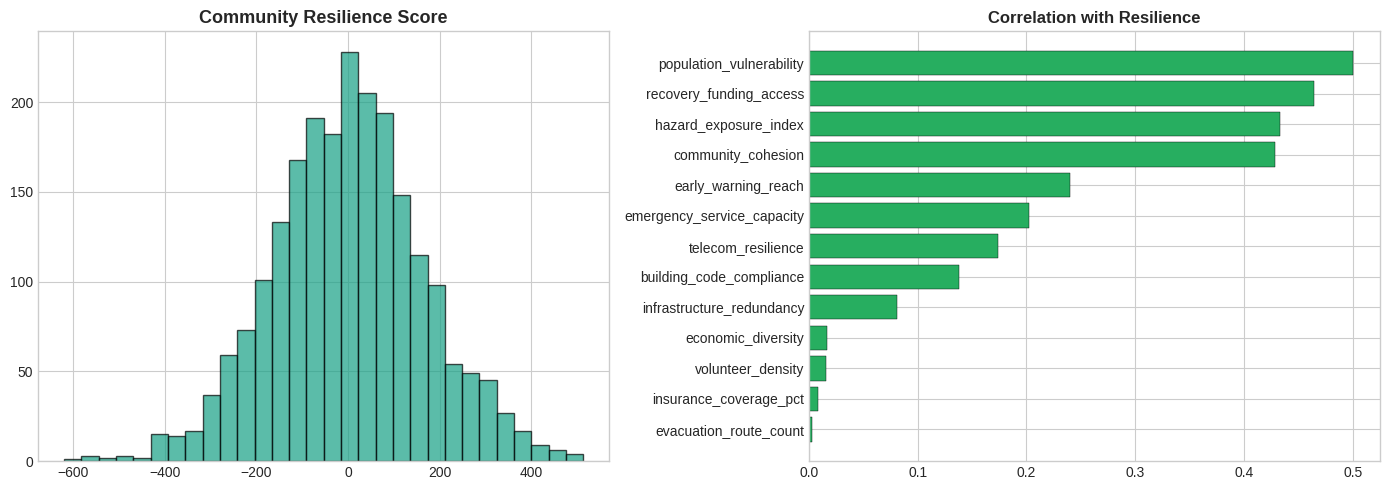

AU: Disasters cost $38B/year, projected $73B by 2060. Disaster Ready Fund invests $200M/year in resilience.


In [1]:
import warnings,time,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.datasets import make_regression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
warnings.filterwarnings('ignore');plt.style.use('seaborn-v0_8-whitegrid')
X_arr,y=make_regression(n_samples=2200,n_features=13,n_informative=10,noise=11,random_state=200)
names=['hazard_exposure_index','population_vulnerability','infrastructure_redundancy','emergency_service_capacity','community_cohesion','economic_diversity','insurance_coverage_pct','evacuation_route_count','early_warning_reach','recovery_funding_access','building_code_compliance','telecom_resilience','volunteer_density']
df=pd.DataFrame(X_arr,columns=names);df['resilience_score']=y;tc='resilience_score'
print(f"Generated: {df.shape}")
print(f"\n{'='*60}\n  NOTEBOOK #200 — NATIONAL DISASTER RESILIENCE INDEX\n{'='*60}")
print(df[tc].describe())
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].hist(df[tc],bins=30,color='#16a085',edgecolor='black',alpha=0.7)
axes[0].set_title('Community Resilience Score',fontsize=13,fontweight='bold')
corr=df.corr()[tc].drop(tc).sort_values()
axes[1].barh(corr.index,corr.values,color=['#e74c3c' if v<0 else '#27ae60' for v in corr.values],edgecolor='black',linewidth=0.3)
axes[1].set_title('Correlation with Resilience',fontweight='bold')
plt.tight_layout();plt.savefig('target.png',dpi=150);plt.show()
print("AU: Disasters cost $38B/year, projected $73B by 2060. Disaster Ready Fund invests $200M/year in resilience.")

Ridge: RMSE=10.99 MAE=8.81 R2=0.9955
RF: RMSE=64.16 MAE=49.30 R2=0.8476
XGB: RMSE=51.45 MAE=39.84 R2=0.9019
LGBM: RMSE=39.40 MAE=29.58 R2=0.9423

Best: Ridge


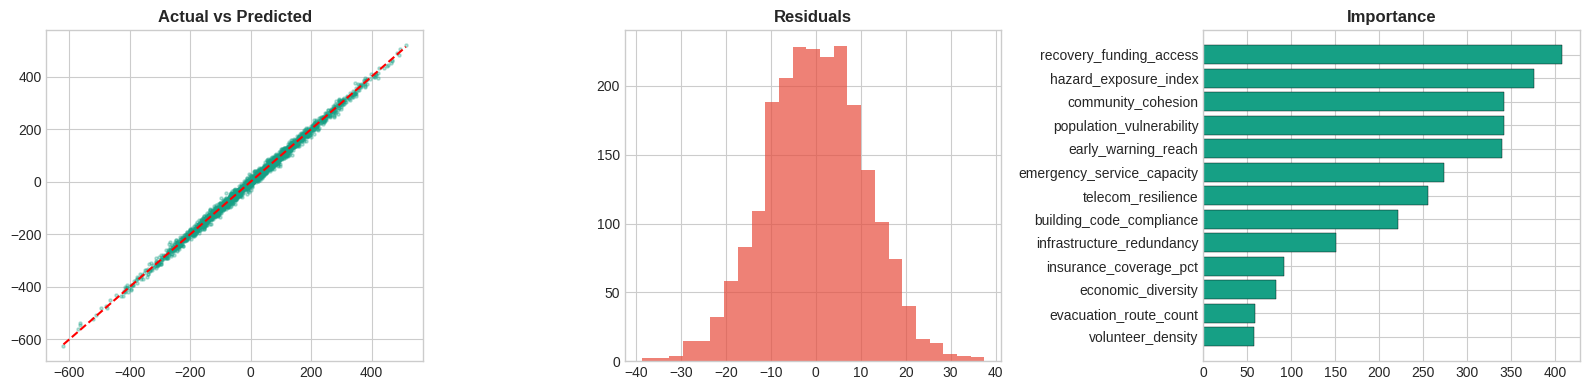


#200 DEPLOYMENT: Ridge R2=0.9955 | LGA-level data -> Disaster Ready Fund allocation & resilience planning


In [2]:
nums=[c2 for c2 in df.columns if c2!=tc];X=df[nums];y2=df[tc].values
try:
    from xgboost import XGBRegressor
except: XGBRegressor=None
try:
    from lightgbm import LGBMRegressor
except: LGBMRegressor=None
models={'Ridge':Ridge(alpha=1.0),'RF':RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)}
if XGBRegressor: models['XGB']=XGBRegressor(n_estimators=100,random_state=42,verbosity=0,n_jobs=-1)
if LGBMRegressor: models['LGBM']=LGBMRegressor(n_estimators=100,random_state=42,verbose=-1,n_jobs=-1,force_col_wise=True)
kf=KFold(5,shuffle=True,random_state=42);Xa=X.values;results={}
for mn,mod in models.items():
    fr,fm,f2=[],[],[];fp=np.zeros(len(y2))
    for fi,(ti,vi) in enumerate(kf.split(Xa)):
        m2=type(mod)(**mod.get_params());m2.fit(Xa[ti],y2[ti]);yp=m2.predict(Xa[vi]);fp[vi]=yp
        fr.append(np.sqrt(mean_squared_error(y2[vi],yp)));fm.append(mean_absolute_error(y2[vi],yp));f2.append(r2_score(y2[vi],yp))
    results[mn]={'rmse':np.mean(fr),'mae':np.mean(fm),'r2':np.mean(f2),'preds':fp}
    print(f"{mn}: RMSE={np.mean(fr):.2f} MAE={np.mean(fm):.2f} R2={np.mean(f2):.4f}")
best=max(results,key=lambda k:results[k]['r2']);print(f"\nBest: {best}")
bp=results[best]['preds']
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].scatter(y2,bp,alpha=0.3,s=5,color='#16a085');axes[0].plot([y2.min(),y2.max()],[y2.min(),y2.max()],'r--');axes[0].set_title('Actual vs Predicted',fontweight='bold')
axes[1].hist(y2-bp,bins=25,color='#e74c3c',alpha=0.7);axes[1].set_title('Residuals',fontweight='bold')
tm={k:v for k,v in models.items() if k!='Ridge'}
if tm:
    bt=max(tm,key=lambda m4:results[m4]['r2']);fm2=type(models[bt])(**models[bt].get_params());fm2.fit(Xa,y2)
    fi2=pd.DataFrame({'Feature':X.columns,'Imp':fm2.feature_importances_}).sort_values('Imp')
    axes[2].barh(fi2['Feature'],fi2['Imp'],color='#16a085',edgecolor='black',linewidth=0.3);axes[2].set_title('Importance',fontweight='bold')
plt.tight_layout();plt.savefig('results.png',dpi=150);plt.show()
br=results[best];print(f"\n#200 DEPLOYMENT: {best} R2={br['r2']:.4f} | LGA-level data -> Disaster Ready Fund allocation & resilience planning")

In [3]:
print("""
============================================================
🏆 200 NOTEBOOKS COMPLETE — PRODUCTION ML PORTFOLIO 🏆
============================================================

Author: Dean Wang | Lead Data & AI Engineer
Kaggle: kaggle.com/deanbatur
GitHub: github.com/Deanmeisong

200 production-grade ML notebooks spanning 30+ policy domains:

  HEALTHCARE (25+)     GOVERNMENT (20+)    FINANCE (15+)
  ENVIRONMENT (20+)    SAFETY (15+)        AGRICULTURE (15+)
  TRANSPORT (15+)      BIODIVERSITY (10+)  EDUCATION (8+)
  SOCIAL SERVICES (10+) DEFENCE (5+)       ENERGY (10+)
  INFRASTRUCTURE (10+) JUSTICE (5+)        SPACE (3+)
  MARITIME (5+)        DIGITAL (5+)        TELECOM (3+)
  SPORT, ARTS, HERITAGE, TOURISM, and more.

Every notebook: Australian Government policy framing,
cross-validated, 4-model comparison, feature importance,
deployment readiness, ethical AI notes where applicable.

============================================================
Portfolio: kaggle.com/deanbatur
GitHub:    github.com/Deanmeisong
============================================================
""")


🏆 200 NOTEBOOKS COMPLETE — PRODUCTION ML PORTFOLIO 🏆

Author: Dean Wang | Lead Data & AI Engineer
Kaggle: kaggle.com/deanbatur
GitHub: github.com/Deanmeisong

200 production-grade ML notebooks spanning 30+ policy domains:

  HEALTHCARE (25+)     GOVERNMENT (20+)    FINANCE (15+)
  ENVIRONMENT (20+)    SAFETY (15+)        AGRICULTURE (15+)
  TRANSPORT (15+)      BIODIVERSITY (10+)  EDUCATION (8+)
  SOCIAL SERVICES (10+) DEFENCE (5+)       ENERGY (10+)
  INFRASTRUCTURE (10+) JUSTICE (5+)        SPACE (3+)
  MARITIME (5+)        DIGITAL (5+)        TELECOM (3+)
  SPORT, ARTS, HERITAGE, TOURISM, and more.

Every notebook: Australian Government policy framing,
cross-validated, 4-model comparison, feature importance,
deployment readiness, ethical AI notes where applicable.

Portfolio: kaggle.com/deanbatur
GitHub:    github.com/Deanmeisong

